# Entregable II — Sección 1: Entrenamiento y evaluación de modelos

**Proyecto:** Estimación del riesgo de diabetes tipo 2 con datos del BRFSS 2025
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia
**Autores:** Alejandro Gallego Alarcón, Andrés Eduardo Pabón Roldán, Paula Andrea Guarín Guarín

Este notebook reproduce todos los resultados de la sección 1 del reporte:

1. Carga de datos y construcción de la variable objetivo.
2. Tratamiento de datos faltantes y codificación.
3. Partición de los datos y metodología de validación.
4. Experimentos preliminares: codificación y manejo del desbalance.
5. Búsqueda de hiperparámetros de los cinco modelos.
6. Resultados de entrenamiento, validación y prueba (con matrices de confusión normalizadas).
7. Verificaciones pedidas en la realimentación del Entregable I: proporcionalidad del orden en las variables ordinales y comparación con `LinearSVC`.

Todas las métricas se reportan con dos cifras decimales; los valores *p* se dejan con cuatro.

Tiempo de ejecución aproximado: 25 a 35 minutos en Google Colab (2 núcleos). Casi todo el tiempo lo consume la máquina de vectores de soporte.

In [1]:
# Solo es necesario en Google Colab; en otros entornos instale con: pip install -r requirements.txt
try:
    import imblearn  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

In [2]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, f1_score, make_scorer, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTE, SMOTEN
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEMILLA = 42           # semilla única para que todo sea reproducible
N_BUSQUEDA = 20_000    # tamaño de la submuestra para la búsqueda de hiperparámetros
N_SVM_FINAL = 40_000   # tamaño de la submuestra para el ajuste final de la SVM
N_FOLDS = 5            # pliegues de la validación cruzada
N_JOBS = 2             # núcleos disponibles (Colab ofrece 2)

os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 1. Carga de datos

El archivo público del BRFSS 2025 se descarga directamente de los CDC y se reduce a las 12 columnas que usa el proyecto (la variable objetivo y 11 predictoras). Si el archivo reducido ya existe en la carpeta, no se vuelve a descargar.

In [3]:
URL_BRFSS = "https://www.cdc.gov/brfss/annual_data/2025/files/LLCP2025XPT.zip"
CSV_REDUCIDO = "brfss2025_reducido.csv"

OBJETIVO = "DIABETE4"
PREDICTORAS = ["_SEX", "_AGEG5YR", "_RACEGR3", "_EDUCAG", "_INCOMG1", "_BMI5CAT",
               "_TOTINDA", "_SMOKER3", "_RFDRHV9", "_FRTLT1A", "_VEGLT1A"]
NOMBRES = {"_SEX": "Sexo", "_AGEG5YR": "Edad", "_RACEGR3": "Raza/etnia",
           "_EDUCAG": "Educación", "_INCOMG1": "Ingreso", "_BMI5CAT": "IMC",
           "_TOTINDA": "Actividad física", "_SMOKER3": "Fumador",
           "_RFDRHV9": "Alcohol excesivo", "_FRTLT1A": "Frutas", "_VEGLT1A": "Vegetales"}

if not os.path.exists(CSV_REDUCIDO):
    import glob, urllib.request, zipfile
    if not glob.glob("LLCP2025*.XPT*"):
        if not os.path.exists("LLCP2025XPT.zip"):
            print("Descargando el BRFSS 2025 desde los CDC (64 MB)...")
            urllib.request.urlretrieve(URL_BRFSS, "LLCP2025XPT.zip")
        with zipfile.ZipFile("LLCP2025XPT.zip") as z:
            z.extractall(".")
    ruta_xpt = glob.glob("LLCP2025*.XPT*")[0]   # el archivo del CDC trae un espacio al final del nombre
    bloques = [b[[OBJETIVO] + PREDICTORAS]
               for b in pd.read_sas(ruta_xpt, format="xport", chunksize=50_000)]
    pd.concat(bloques, ignore_index=True).to_csv(CSV_REDUCIDO, index=False)

datos = pd.read_csv(CSV_REDUCIDO)
print("Registros y columnas del archivo:", datos.shape)
print("\nDistribución de DIABETE4 (códigos del codebook):")
print(datos[OBJETIVO].value_counts(dropna=False).sort_index())

Registros y columnas del archivo: (356158, 12)

Distribución de DIABETE4 (códigos del codebook):
DIABETE4
1.0     51827
2.0      2671
3.0    290712
4.0     10166
7.0       580
9.0       196
NaN         6
Name: count, dtype: int64


### Variable objetivo

Se conservan solo las respuestas «sí» (código 1, clase positiva) y «no» (código 3, clase negativa). Se excluyen la diabetes gestacional (2), la prediabetes (4), «no sabe» (7), «rehusó» (9) y las respuestas en blanco.

In [4]:
muestra = datos[datos[OBJETIVO].isin([1, 3])].reset_index(drop=True)
y = (muestra[OBJETIVO] == 1).astype(int)
print(f"Muestra analítica: {len(muestra):,} registros")
print(f"Positivos: {y.sum():,} ({y.mean():.2%})   Negativos: {(1 - y).sum():,} ({1 - y.mean():.2%})")

Muestra analítica: 342,539 registros
Positivos: 51,827 (15.13%)   Negativos: 290,712 (84.87%)


## 2. Datos faltantes y codificación

En el BRFSS, «no sabe» y «rehusó» traen un código numérico propio (9 en casi todas las variables calculadas, 14 en la edad). En `_BMI5CAT` y en unos pocos registros de `_RACEGR3` los faltantes vienen como celdas vacías. Todos se unifican como `NaN`.

Además del porcentaje de faltantes, se revisa si **no responder está asociado con la diabetes**: para cada variable se compara la prevalencia entre quienes respondieron y quienes no. Para no usar información del conjunto de prueba, esta tabla se calcula más abajo solo con el conjunto de entrenamiento.

In [5]:
CODIGO_FALTANTE = {c: 9 for c in PREDICTORAS}
CODIGO_FALTANTE["_AGEG5YR"] = 14

X = muestra[PREDICTORAS].copy()
for c in PREDICTORAS:
    X[c] = X[c].where(X[c] != CODIGO_FALTANTE[c])   # el código de «no sabe/rehusó» pasa a NaN

print("Categorías válidas por variable:")
for c in PREDICTORAS:
    print(f"  {c:10s} {NOMBRES[c]:18s} {sorted(X[c].dropna().unique().astype(int).tolist())}")

Categorías válidas por variable:
  _SEX       Sexo               [1, 2]
  _AGEG5YR   Edad               [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
  _RACEGR3   Raza/etnia         [1, 2, 3, 4, 5]
  _EDUCAG    Educación          [1, 2, 3, 4]
  _INCOMG1   Ingreso            [1, 2, 3, 4, 5, 6, 7]
  _BMI5CAT   IMC                [1, 2, 3, 4]
  _TOTINDA   Actividad física   [1, 2]
  _SMOKER3   Fumador            [1, 2, 3, 4]
  _RFDRHV9   Alcohol excesivo   [1, 2]
  _FRTLT1A   Frutas             [1, 2]
  _VEGLT1A   Vegetales          [1, 2]


## 3. Partición de los datos y metodología de validación

- **Prueba (20 %):** partición estratificada que se aparta desde el inicio y solo se usa una vez, para la evaluación final.
- **Entrenamiento (80 %):** aquí se hace todo lo demás.
- **Búsqueda de hiperparámetros:** validación cruzada estratificada de 5 pliegues sobre una submuestra estratificada de 20.000 registros del conjunto de entrenamiento. La submuestra es necesaria porque la SVM con kernel y el KNN no escalan a 274.000 registros.
- **Sin fuga de información:** la imputación, la codificación y el balanceo van dentro de un *pipeline*, de modo que en cada pliegue se ajustan solo con los datos de entrenamiento de ese pliegue.
- **Intervalos de confianza:** con los 5 valores de cada métrica (uno por pliegue) se calcula un intervalo del 95 % con la distribución *t* de Student (4 grados de libertad).

In [6]:
X_ent, X_pru, y_ent, y_pru = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

X_bus, _, y_bus, _ = train_test_split(
    X_ent, y_ent, train_size=N_BUSQUEDA, stratify=y_ent, random_state=SEMILLA)

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)

for nombre, yy in [("Entrenamiento", y_ent), ("Prueba", y_pru), ("Submuestra de búsqueda", y_bus)]:
    print(f"{nombre:24s} n = {len(yy):>7,}   positivos = {yy.mean():.2%}")

Entrenamiento            n = 274,031   positivos = 15.13%
Prueba                   n =  68,508   positivos = 15.13%
Submuestra de búsqueda   n =  20,000   positivos = 15.13%


In [7]:
# ¿No responder es en sí mismo un predictor? (solo con el conjunto de entrenamiento)
filas = []
for c in PREDICTORAS:
    falta = X_ent[c].isna()
    if falta.sum() == 0:
        continue
    tabla = pd.crosstab(falta, y_ent)
    filas.append({"Variable": NOMBRES[c],
                  "% faltantes": 100 * falta.mean(),
                  "Prevalencia si respondió (%)": 100 * y_ent[~falta].mean(),
                  "Prevalencia si no respondió (%)": 100 * y_ent[falta].mean(),
                  "valor p (chi-cuadrado)": stats.chi2_contingency(tabla)[1]})
tabla_faltantes = pd.DataFrame(filas).round({"% faltantes": 2,
                                             "Prevalencia si respondió (%)": 2,
                                             "Prevalencia si no respondió (%)": 2})
tabla_faltantes.to_csv("resultados/faltantes_vs_diabetes.csv", index=False)
tabla_faltantes

,Variable,% faltantes,Prevalencia si respondió (%),Prevalencia si no respondió (%),valor p (chi-cuadrado)
0,Edad,1.85,15.17,12.79,2.864453e-06
1,Raza/etnia,2.30,15.14,14.68,3.200950e-01
2,Educación,0.58,15.15,11.99,5.031777e-04
3,Ingreso,19.85,15.15,15.05,5.418189e-01
4,IMC,9.08,15.27,13.71,6.354219e-11
5,Actividad física,0.26,15.11,21.15,8.951454e-06
6,Fumador,5.79,15.22,13.59,2.673792e-08
7,Alcohol excesivo,8.10,15.31,13.11,2.177912e-18
8,Frutas,13.05,15.17,14.85,1.200324e-01
9,Vegetales,15.05,15.17,14.90,1.578453e-01


### Métricas y funciones auxiliares

- **AUC-ROC:** criterio para elegir hiperparámetros. No depende del umbral de decisión ni se ve afectado por el desbalance.
- **Sensibilidad:** métrica clave de monitoreo. En tamizaje, un falso negativo (no detectar a alguien con diabetes) cuesta más que un falso positivo.
- **Especificidad, precisión y F1:** muestran el costo de esa sensibilidad en falsas alarmas.

La exactitud no se usa como criterio: un modelo que siempre predice «no» alcanzaría 84,87 % sin detectar ningún caso.

In [8]:
METRICAS = {
    "auc": "roc_auc",
    "sens": "recall",
    "espec": make_scorer(recall_score, pos_label=0),
    "prec": make_scorer(precision_score, zero_division=0),
    "f1": "f1",
}
ETIQUETA = {"auc": "AUC", "sens": "Sensibilidad", "espec": "Especificidad",
            "prec": "Precisión", "f1": "F1"}


def ic95(valores):
    # Semiancho del intervalo de confianza del 95 % (t de Student) para la media de los pliegues
    v = np.asarray(valores, dtype=float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))


def evaluar_cv(modelo, Xd=None, yd=None):
    # Validación cruzada de un pipeline; devuelve los valores por pliegue de cada métrica
    Xd = X_bus if Xd is None else Xd
    yd = y_bus if yd is None else yd
    r = cross_validate(modelo, Xd, yd, cv=cv, scoring=METRICAS,
                       return_train_score=True, n_jobs=N_JOBS)
    return {f"{parte}_{m}": r[f"{clave}_{m}"]
            for parte, clave in [("ent", "train"), ("val", "test")] for m in METRICAS}


def resumen(res, parte="val", metricas=("auc", "sens", "espec", "f1")):
    return {ETIQUETA[m]: f"{res[f'{parte}_{m}'].mean():.2f} ± {ic95(res[f'{parte}_{m}']):.2f}"
            for m in metricas}

### Preprocesamiento base

Todas las predictoras son categóricas. El preprocesamiento base es:

1. **Faltantes:** se reemplazan por una categoría propia «no reportado» (código 0, que ninguna variable usa).
2. **Codificación *one-hot*** de las 11 variables, incluida la categoría «no reportado». Resultan 57 columnas binarias.

Como todas las columnas quedan en {0, 1}, no hace falta escalar para KNN, SVM ni la red neuronal.

In [9]:
def _submuestrear_y_barajar(Xd, yd):
    Xr, yr = RandomUnderSampler(random_state=SEMILLA).fit_resample(Xd, yd)
    orden = np.random.default_rng(SEMILLA).permutation(len(yr))
    return np.asarray(Xr)[orden], np.asarray(yr)[orden]


def submuestreo():
    # Submuestreo aleatorio de la clase mayoritaria, seguido de un barajado de las filas.
    # El barajado importa para KNN: con datos categóricos hay muchos vecinos a la misma distancia,
    # scikit-learn desempata por orden de aparición y el submuestreo deja primero a todos los negativos.
    return FunctionSampler(func=_submuestrear_y_barajar, validate=False)


def pasos_onehot():
    # Imputación por categoría propia + one-hot. Se ajusta solo con los datos de entrenamiento.
    return [("imputar", SimpleImputer(strategy="constant", fill_value=0)),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]


n_columnas = SkPipeline(pasos_onehot()).fit_transform(X_bus).shape[1]
print("Columnas después de la codificación one-hot:", n_columnas)

Columnas después de la codificación one-hot: 57


## 4. Experimentos preliminares

### 4.1 Codificación de las variables ordinales e imputación

Edad, educación, ingreso e IMC tienen un orden natural. Tratarlas como enteros supone que pasar de una categoría a la siguiente tiene siempre el mismo efecto, lo que puede no cumplirse. Se comparan tres alternativas en los cinco modelos, cada uno con hiperparámetros intermedios fijos:

- **A. *One-hot* + «no reportado»** (preprocesamiento base).
- **B. Ordinal + moda:** las cuatro ordinales como enteros estandarizados, las demás en *one-hot*; los faltantes se imputan con la moda del conjunto de entrenamiento.
- **C. Ordinal + moda + indicador:** igual que B, añadiendo una columna binaria por variable que marca si el dato faltaba.

**Regla de decisión:** cada modelo usa la codificación A, salvo que B o C la superen en AUC de validación con una diferencia significativa (prueba *t* pareada sobre los mismos pliegues, p < 0,05).

In [10]:
ORDINALES = ["_AGEG5YR", "_EDUCAG", "_INCOMG1", "_BMI5CAT"]
NOMINALES = [c for c in PREDICTORAS if c not in ORDINALES]
CODIFICACIONES = {"A": "A. One-hot + «no reportado»", "B": "B. Ordinal + moda",
                  "C": "C. Ordinal + moda + indicador"}


def prep_ordinal(indicador):
    return ColumnTransformer([
        ("ord", SkPipeline([("imputar", SimpleImputer(strategy="most_frequent", add_indicator=indicador)),
                            ("escalar", StandardScaler())]), ORDINALES),
        ("nom", SkPipeline([("imputar", SimpleImputer(strategy="most_frequent", add_indicator=indicador)),
                            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), NOMINALES),
    ])


def crear_pipeline(clasificador, codificacion="A", submuestrear=False):
    # Pipeline completo: preprocesamiento + (submuestreo opcional) + clasificador.
    # imblearn aplica el muestreo solo al ajustar, nunca al predecir.
    pasos = pasos_onehot() if codificacion == "A" else [("prep", prep_ordinal(codificacion == "C"))]
    if submuestrear:
        pasos = pasos + [("balancear", submuestreo())]
    return Pipeline(pasos + [("modelo", clasificador)])


# Clasificador con hiperparámetros intermedios y si necesita submuestreo (no acepta class_weight)
BASE = {
    "Regresión logística": (lambda: LogisticRegression(class_weight="balanced", max_iter=2000), False),
    "KNN": (lambda: KNeighborsClassifier(n_neighbors=51), True),
    "Bosque aleatorio": (lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                                        class_weight="balanced", random_state=SEMILLA), False),
    "Red neuronal (MLP)": (lambda: MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=300, early_stopping=True,
                                                 n_iter_no_change=10, random_state=SEMILLA), True),
    "SVM (RBF)": (lambda: SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced"), False),
}

filas, cv_codificacion = [], {}
for nombre_modelo, (crear, submuestrear) in BASE.items():
    for clave, variante in CODIFICACIONES.items():
        res = evaluar_cv(crear_pipeline(crear(), clave, submuestrear))
        cv_codificacion[(nombre_modelo, clave)] = res
        filas.append({"Modelo": nombre_modelo, "Codificación": variante, **resumen(res)})

tabla_codificacion = pd.DataFrame(filas)
tabla_codificacion.to_csv("resultados/comparacion_codificacion.csv", index=False)
tabla_codificacion

,Modelo,Codificación,AUC,Sensibilidad,Especificidad,F1
0,Regresión logística,A. One-hot + «no reportado»,0.76 ± 0.01,0.75 ± 0.01,0.64 ± 0.01,0.40 ± 0.01
1,Regresión logística,B. Ordinal + moda,0.75 ± 0.01,0.72 ± 0.01,0.65 ± 0.01,0.39 ± 0.01
2,Regresión logística,C. Ordinal + moda + indicador,0.75 ± 0.01,0.72 ± 0.02,0.66 ± 0.01,0.39 ± 0.01
3,KNN,A. One-hot + «no reportado»,0.70 ± 0.01,0.66 ± 0.03,0.63 ± 0.02,0.35 ± 0.01
4,KNN,B. Ordinal + moda,0.74 ± 0.01,0.74 ± 0.01,0.62 ± 0.01,0.38 ± 0.01
5,KNN,C. Ordinal + moda + indicador,0.73 ± 0.01,0.72 ± 0.01,0.63 ± 0.01,0.38 ± 0.01
6,Bosque aleatorio,A. One-hot + «no reportado»,0.75 ± 0.01,0.72 ± 0.02,0.65 ± 0.02,0.39 ± 0.01
7,Bosque aleatorio,B. Ordinal + moda,0.75 ± 0.01,0.74 ± 0.02,0.63 ± 0.02,0.39 ± 0.01
8,Bosque aleatorio,C. Ordinal + moda + indicador,0.75 ± 0.01,0.74 ± 0.02,0.64 ± 0.02,0.39 ± 0.01
9,Red neuronal (MLP),A. One-hot + «no reportado»,0.75 ± 0.01,0.74 ± 0.05,0.64 ± 0.03,0.39 ± 0.01


In [11]:
# Regla de decisión: A por defecto; B o C solo si mejoran el AUC de validación con p < 0,05
CODIFICACION, filas = {}, []
for modelo in BASE:
    a = cv_codificacion[(modelo, "A")]["val_auc"]
    elegida, mejor_auc = "A", a.mean()
    for otra in ["B", "C"]:
        b = cv_codificacion[(modelo, otra)]["val_auc"]
        t, p = stats.ttest_rel(b, a)
        filas.append({"Modelo": modelo, "Comparación": f"{otra} − A",
                      "Diferencia media de AUC": round((b - a).mean(), 4), "valor p": round(p, 4)})
        if p < 0.05 and b.mean() > mejor_auc:
            elegida, mejor_auc = otra, b.mean()
    CODIFICACION[modelo] = elegida
prueba_codificacion = pd.DataFrame(filas)
prueba_codificacion.to_csv("resultados/prueba_codificacion.csv", index=False)
print("Codificación elegida por modelo:", CODIFICACION)
prueba_codificacion

Codificación elegida por modelo: {'Regresión logística': 'A', 'KNN': 'B', 'Bosque aleatorio': 'A', 'Red neuronal (MLP)': 'A', 'SVM (RBF)': 'C'}


,Modelo,Comparación,Diferencia media de AUC,valor p
0,Regresión logística,B − A,-0.0066,0.0008
1,Regresión logística,C − A,-0.0046,0.0070
2,KNN,B − A,0.0424,0.0003
3,KNN,C − A,0.0381,0.0001
4,Bosque aleatorio,B − A,0.0034,0.1809
5,Bosque aleatorio,C − A,0.0035,0.1348
6,Red neuronal (MLP),B − A,0.0006,0.7974
7,Red neuronal (MLP),C − A,-0.0018,0.7298
8,SVM (RBF),B − A,0.0113,0.0121
9,SVM (RBF),C − A,0.0144,0.0017


### 4.1.1 ¿El orden de las ordinales es proporcional?

La profesora pidió verificar si, para modelos lineales y de distancia, el paso entre categorías consecutivas tiene el mismo efecto (por ejemplo, del grupo de edad 1 al 2 frente al 12 al 13). Se ajusta la regresión logística con codificación *one-hot* sobre el conjunto de entrenamiento y se grafican sus coeficientes por categoría: si el orden fuera proporcional, los puntos quedarían sobre una recta.

Nota: el proyecto usa las variables calculadas por el CDC (`_EDUCAG`, 4 niveles; `_INCOMG1`, 7 niveles), no las preguntas originales `EDUCA` (6 niveles) e `INCOME3` (11 niveles).

,Variable,R² del ajuste lineal,Paso mínimo,Paso máximo
0,Edad,0.91,-0.16,0.49
1,Educación,0.87,-0.21,0.02
2,Ingreso,0.96,-0.32,-0.06
3,IMC,0.98,0.39,0.69


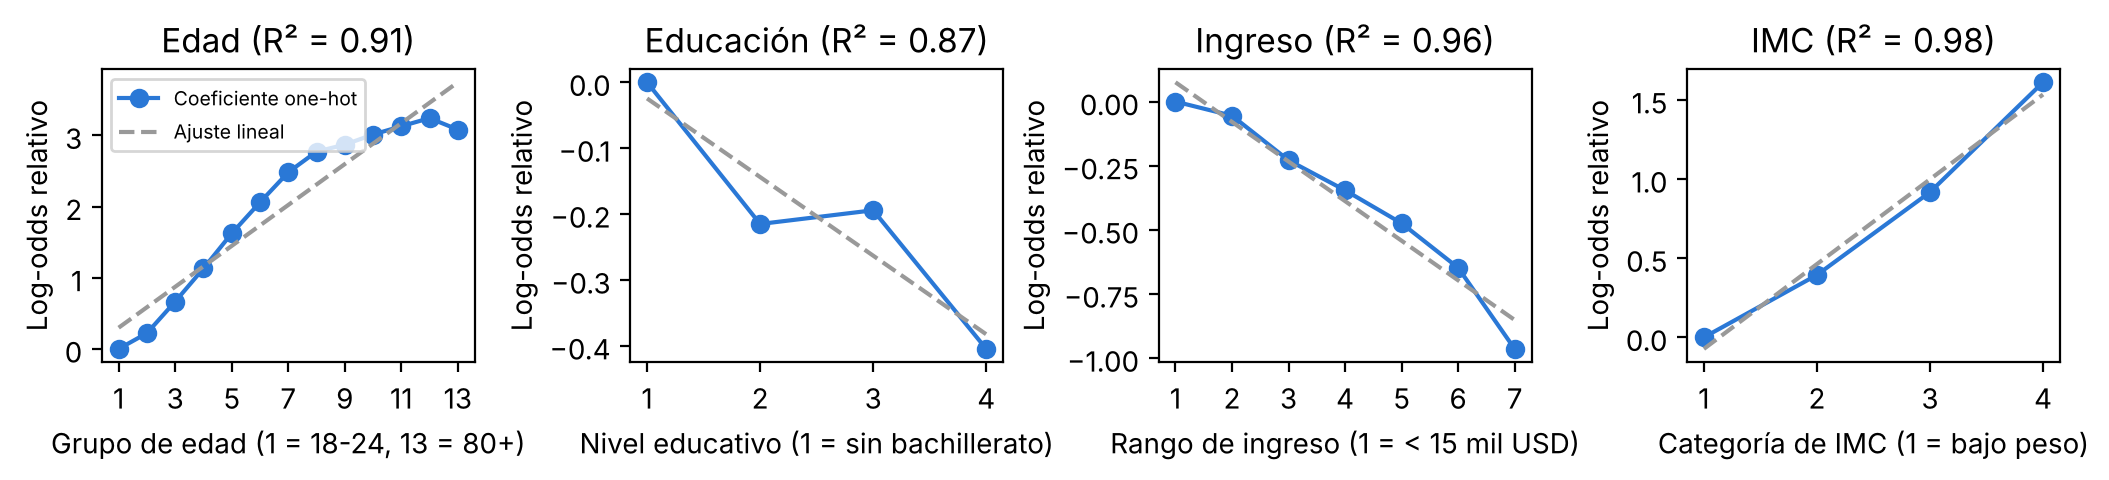

In [12]:
lr_onehot = crear_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000), "A").fit(X_ent, y_ent)
nombres_cols = lr_onehot.named_steps["onehot"].get_feature_names_out(PREDICTORAS)
coef = pd.Series(lr_onehot.named_steps["modelo"].coef_[0], index=nombres_cols)

ETIQ_X = {"_AGEG5YR": "Grupo de edad (1 = 18-24, 13 = 80+)", "_EDUCAG": "Nivel educativo (1 = sin bachillerato)",
          "_INCOMG1": "Rango de ingreso (1 = < 15 mil USD)", "_BMI5CAT": "Categoría de IMC (1 = bajo peso)"}
fig, ejes = plt.subplots(1, 4, figsize=(10.5, 2.5))
filas = []
for ax, c in zip(ejes, ORDINALES):
    niveles = sorted(X_ent[c].dropna().unique().astype(int))
    b = np.array([coef[f"{c}_{float(k)}"] for k in niveles])
    b = b - b[0]                                  # efecto relativo a la primera categoría
    ajuste = np.polyfit(niveles, b, 1)
    r2 = 1 - ((b - np.polyval(ajuste, niveles)) ** 2).sum() / ((b - b.mean()) ** 2).sum()
    pasos = np.diff(b)
    filas.append({"Variable": NOMBRES[c], "R² del ajuste lineal": round(r2, 2),
                  "Paso mínimo": round(pasos.min(), 2), "Paso máximo": round(pasos.max(), 2)})
    ax.plot(niveles, b, marker="o", color=COLORES[0] if "COLORES" in globals() else "#2a78d6", label="Coeficiente one-hot")
    ax.plot(niveles, np.polyval(ajuste, niveles), linestyle="--", color="#999999", label="Ajuste lineal")
    ax.set(title=f"{NOMBRES[c]} (R² = {r2:.2f})", xlabel=ETIQ_X[c], ylabel="Log-odds relativo")
    ax.set_xticks(niveles[::2] if len(niveles) > 8 else niveles)
ejes[0].legend(loc="upper left", fontsize=7)
fig.tight_layout()
fig.savefig("figuras/proporcionalidad_ordinales.pdf", bbox_inches="tight")
fig.savefig("figuras/proporcionalidad_ordinales.png", dpi=200, bbox_inches="tight")
tabla_prop = pd.DataFrame(filas)
tabla_prop.to_csv("resultados/proporcionalidad_ordinales.csv", index=False)
tabla_prop

### 4.2 Manejo del desbalance de clases

Con 15,13 % de positivos, un modelo sin corrección tiende a predecir casi siempre «no». Se comparan cinco estrategias, todas aplicadas **solo dentro de los pliegues de entrenamiento**:

- **Sin corrección.**
- **Ponderación de clases** (`class_weight="balanced"`).
- **SMOTE** clásico sobre las columnas *one-hot*, que genera positivos sintéticos por interpolación.
- **SMOTEN**, la variante de SMOTE para variables categóricas.
- **Submuestreo aleatorio** de la clase mayoritaria.

Se usa la regresión logística y el bosque aleatorio, que aceptan las cinco.

In [13]:
def variantes_balanceo(crear):
    # crear(peso) devuelve el clasificador con o sin class_weight
    imputar, onehot = pasos_onehot()
    return {
        "Sin corrección": Pipeline([imputar, onehot, ("modelo", crear(None))]),
        "Ponderación de clases": Pipeline([imputar, onehot, ("modelo", crear("balanced"))]),
        "SMOTE": Pipeline([imputar, onehot, ("balancear", SMOTE(random_state=SEMILLA)),
                           ("modelo", crear(None))]),
        # SMOTEN trabaja sobre las categorías originales, por eso va antes del one-hot
        "SMOTEN": Pipeline([imputar, ("balancear", SMOTEN(random_state=SEMILLA)),
                                    onehot, ("modelo", crear(None))]),
        "Submuestreo aleatorio": Pipeline([imputar, onehot,
                                           ("balancear", submuestreo()),
                                           ("modelo", crear(None))]),
    }


modelos_balanceo = {
    "Regresión logística": lambda peso: LogisticRegression(class_weight=peso, max_iter=2000),
    "Bosque aleatorio": lambda peso: RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, class_weight=peso, random_state=SEMILLA),
}

filas, cv_balanceo = [], {}
for nombre_modelo, crear in modelos_balanceo.items():
    for estrategia, pipe in variantes_balanceo(crear).items():
        t0 = time.time()
        res = evaluar_cv(pipe)
        cv_balanceo[(nombre_modelo, estrategia)] = res
        filas.append({"Modelo": nombre_modelo, "Estrategia": estrategia, **resumen(res),
                      "Tiempo (s)": round(time.time() - t0, 1)})

tabla_balanceo = pd.DataFrame(filas)
tabla_balanceo.to_csv("resultados/comparacion_balanceo.csv", index=False)
tabla_balanceo

/usr/local/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,Modelo,Estrategia,AUC,Sensibilidad,Especificidad,F1,Tiempo (s)
0,Regresión logística,Sin corrección,0.76 ± 0.01,0.04 ± 0.01,0.99 ± 0.00,0.08 ± 0.01,0.6
1,Regresión logística,Ponderación de clases,0.76 ± 0.01,0.75 ± 0.01,0.64 ± 0.01,0.40 ± 0.01,0.6
2,Regresión logística,SMOTE,0.75 ± 0.01,0.74 ± 0.02,0.64 ± 0.01,0.39 ± 0.01,1.0
3,Regresión logística,SMOTEN,0.72 ± 0.01,0.64 ± 0.02,0.67 ± 0.00,0.37 ± 0.01,13.8
4,Regresión logística,Submuestreo aleatorio,0.76 ± 0.01,0.74 ± 0.01,0.64 ± 0.02,0.40 ± 0.01,0.5
5,Bosque aleatorio,Sin corrección,0.74 ± 0.01,0.00 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,10.9
6,Bosque aleatorio,Ponderación de clases,0.75 ± 0.01,0.72 ± 0.02,0.65 ± 0.02,0.39 ± 0.01,12.2
7,Bosque aleatorio,SMOTE,0.74 ± 0.01,0.42 ± 0.03,0.84 ± 0.01,0.36 ± 0.01,22.0
8,Bosque aleatorio,SMOTEN,0.71 ± 0.01,0.53 ± 0.02,0.75 ± 0.01,0.36 ± 0.01,26.5
9,Bosque aleatorio,Submuestreo aleatorio,0.74 ± 0.01,0.72 ± 0.01,0.63 ± 0.02,0.38 ± 0.01,5.9


In [14]:
# ¿SMOTE o SMOTEN mejoran de forma significativa frente a la ponderación de clases?
# Prueba t pareada sobre los mismos pliegues
filas = []
for modelo in modelos_balanceo:
    pesos = cv_balanceo[(modelo, "Ponderación de clases")]
    for variante in ["SMOTE", "SMOTEN"]:
        smote = cv_balanceo[(modelo, variante)]
        for m in ["auc", "sens", "f1"]:
            dif = smote[f"val_{m}"] - pesos[f"val_{m}"]
            t, p = stats.ttest_rel(smote[f"val_{m}"], pesos[f"val_{m}"])
            filas.append({"Modelo": modelo, "Comparación": f"{variante} − ponderación",
                          "Métrica": ETIQUETA[m], "Diferencia media": round(dif.mean(), 4),
                          "valor p": round(p, 4)})
prueba_smote = pd.DataFrame(filas)
prueba_smote.to_csv("resultados/prueba_smote_vs_pesos.csv", index=False)
prueba_smote

,Modelo,Comparación,Métrica,Diferencia media,valor p
0,Regresión logística,SMOTE − ponderación,AUC,-0.0038,0.0005
1,Regresión logística,SMOTE − ponderación,Sensibilidad,-0.0102,0.0301
2,Regresión logística,SMOTE − ponderación,F1,-0.0046,0.1717
3,Regresión logística,SMOTEN − ponderación,AUC,-0.0394,0.0018
4,Regresión logística,SMOTEN − ponderación,Sensibilidad,-0.1107,0.0001
5,Regresión logística,SMOTEN − ponderación,F1,-0.0295,0.0021
6,Bosque aleatorio,SMOTE − ponderación,AUC,-0.0063,0.0646
7,Bosque aleatorio,SMOTE − ponderación,Sensibilidad,-0.2987,0.0000
8,Bosque aleatorio,SMOTE − ponderación,F1,-0.0269,0.0135
9,Bosque aleatorio,SMOTEN − ponderación,AUC,-0.0380,0.0008


## 5. Búsqueda de hiperparámetros

Se comparan cinco modelos, uno por cada familia que exige la guía:

| Familia | Modelo | Manejo del desbalance |
|---|---|---|
| Paramétrico | Regresión logística (L2) | Ponderación de clases |
| No paramétrico | K vecinos más cercanos | Submuestreo aleatorio |
| Ensamble de árboles | Bosque aleatorio | Ponderación de clases |
| Red neuronal | Perceptrón multicapa | Submuestreo aleatorio |
| Vectores de soporte | SVM con kernel RBF | Ponderación de clases |

KNN y el perceptrón multicapa de scikit-learn no aceptan `class_weight`; por eso usan submuestreo aleatorio dentro del *pipeline*. Después del submuestreo las filas se barajan: con datos categóricos muchos vecinos quedan a la misma distancia, scikit-learn desempata por orden de aparición y, sin barajar, KNN favorecería de forma artificial a la clase negativa.

Cada combinación de la malla se evalúa con la validación cruzada de 5 pliegues. Se elige la de mayor AUC medio de validación.

In [15]:
ARCHIVO = {"Regresión logística": "logistica", "KNN": "knn", "Bosque aleatorio": "bosque",
           "Red neuronal (MLP)": "mlp", "SVM (RBF)": "svm"}

MODELOS = {
    "Regresión logística": {
        "pipeline": crear_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000), CODIFICACION["Regresión logística"]),
        "malla": {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    },
    "KNN": {
        "pipeline": crear_pipeline(KNeighborsClassifier(), CODIFICACION["KNN"], submuestrear=True),
        "malla": {"modelo__n_neighbors": [5, 15, 31, 51, 101, 201, 401],
                  "modelo__weights": ["uniform", "distance"]},
    },
    "Bosque aleatorio": {
        "pipeline": crear_pipeline(RandomForestClassifier(class_weight="balanced", random_state=SEMILLA),
                                   CODIFICACION["Bosque aleatorio"]),
        "malla": {"modelo__n_estimators": [100, 300],
                  "modelo__max_depth": [4, 8, 12, None],
                  "modelo__min_samples_leaf": [1, 10, 50]},
    },
    "Red neuronal (MLP)": {
        "pipeline": crear_pipeline(MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=10,
                                                 random_state=SEMILLA),
                                   CODIFICACION["Red neuronal (MLP)"], submuestrear=True),
        "malla": {"modelo__hidden_layer_sizes": [(16,), (64,), (32, 16), (64, 32)],
                  "modelo__alpha": [0.0001, 0.01, 0.1, 1.0]},
    },
    "SVM (RBF)": {
        "pipeline": crear_pipeline(SVC(kernel="rbf", class_weight="balanced"), CODIFICACION["SVM (RBF)"]),
        "malla": {"modelo__C": [0.1, 1, 10],
                  "modelo__gamma": [0.001, 0.01, 0.1]},
    },
}

busquedas, tablas_cv = {}, {}
for nombre, cfg in MODELOS.items():
    t0 = time.time()
    gs = GridSearchCV(cfg["pipeline"], cfg["malla"], scoring=METRICAS, refit=False, cv=cv,
                      return_train_score=True, n_jobs=N_JOBS)
    gs.fit(X_bus, y_bus)
    r = pd.DataFrame(gs.cv_results_)
    # Intervalo de confianza del 95 % de cada métrica, a partir de los valores por pliegue
    for parte in ["train", "test"]:
        for m in METRICAS:
            cols = [f"split{i}_{parte}_{m}" for i in range(N_FOLDS)]
            r[f"ic_{parte}_{m}"] = r[cols].apply(ic95, axis=1)
    busquedas[nombre], tablas_cv[nombre] = gs, r
    mejor = r.loc[r["mean_test_auc"].idxmax()]
    print(f"{nombre:20s} {len(r):>3} combinaciones  {time.time() - t0:6.0f} s   "
          f"AUC val = {mejor['mean_test_auc']:.4f} ± {mejor['ic_test_auc']:.4f}   {mejor['params']}")
    r.drop(columns=[c for c in r.columns if c.startswith("split")]).to_csv(
        f"resultados/malla_{ARCHIVO[nombre]}.csv", index=False)

Regresión logística    6 combinaciones       3 s   AUC val = 0.7579 ± 0.0119   {'modelo__C': 1}


/usr/local/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


KNN                   14 combinaciones     151 s   AUC val = 0.7478 ± 0.0100   {'modelo__n_neighbors': 401, 'modelo__weights': 'uniform'}


Bosque aleatorio      24 combinaciones     301 s   AUC val = 0.7473 ± 0.0121   {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 100}


Red neuronal (MLP)    16 combinaciones      30 s   AUC val = 0.7536 ± 0.0102   {'modelo__alpha': 0.0001, 'modelo__hidden_layer_sizes': (16,)}


SVM (RBF)              9 combinaciones    1136 s   AUC val = 0.7557 ± 0.0130   {'modelo__C': 1, 'modelo__gamma': 0.01}


### Efecto de los hiperparámetros

Las tablas muestran, para cada combinación, el AUC y la sensibilidad en entrenamiento y validación (media ± intervalo de confianza del 95 %). La separación entre entrenamiento y validación indica sobreajuste.

In [16]:
def tabla_malla(nombre):
    r = tablas_cv[nombre]
    t = pd.DataFrame({c.replace("param_modelo__", ""): r[c] for c in r.columns if c.startswith("param_")})
    for parte, etiqueta in [("train", "ent."), ("test", "val.")]:
        for m in ["auc", "sens"]:
            t[f"{ETIQUETA[m]} {etiqueta}"] = [f"{a:.2f} ± {b:.2f}" for a, b in
                                              zip(r[f"mean_{parte}_{m}"], r[f"ic_{parte}_{m}"])]
    return t


for nombre in MODELOS:
    print(f"\n=== {nombre} ===")
    print(tabla_malla(nombre).to_string(index=False))


=== Regresión logística ===
      C    AUC ent. Sensibilidad ent.    AUC val. Sensibilidad val.
  0.001 0.73 ± 0.00       0.65 ± 0.01 0.72 ± 0.01       0.64 ± 0.02
  0.010 0.76 ± 0.00       0.72 ± 0.01 0.75 ± 0.01       0.71 ± 0.02
  0.100 0.76 ± 0.00       0.75 ± 0.01 0.76 ± 0.01       0.75 ± 0.01
  1.000 0.76 ± 0.00       0.76 ± 0.01 0.76 ± 0.01       0.75 ± 0.01
 10.000 0.76 ± 0.00       0.76 ± 0.01 0.76 ± 0.01       0.75 ± 0.01
100.000 0.76 ± 0.00       0.76 ± 0.01 0.76 ± 0.01       0.75 ± 0.01

=== KNN ===
 n_neighbors  weights    AUC ent. Sensibilidad ent.    AUC val. Sensibilidad val.
           5  uniform 0.77 ± 0.00       0.79 ± 0.01 0.68 ± 0.01       0.67 ± 0.01
           5 distance 0.91 ± 0.00       0.90 ± 0.01 0.66 ± 0.00       0.64 ± 0.02
          15  uniform 0.76 ± 0.00       0.77 ± 0.01 0.72 ± 0.01       0.72 ± 0.01
          15 distance 0.92 ± 0.00       0.90 ± 0.01 0.68 ± 0.01       0.68 ± 0.02
          31  uniform 0.75 ± 0.00       0.76 ± 0.01 0.73 ± 0.01       0.

In [17]:
# Figura: efecto de los hiperparámetros sobre el AUC (línea continua: validación; punteada: entrenamiento)
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
MARCAS = ["o", "s", "^", "D", "v"]
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
                     "legend.frameon": False, "legend.fontsize": 7.5, "lines.linewidth": 1.6,
                     "lines.markersize": 4.5})


def curvas(ax, r, eje_x, grupo=None, etiqueta_grupo="{}", filtro=None, logx=False):
    # Dibuja AUC de validación (con banda del IC 95 %) y de entrenamiento frente a un hiperparámetro
    d = r if filtro is None else r[filtro(r)]
    grupos = [None] if grupo is None else list(dict.fromkeys(d[grupo].tolist()))
    for i, g in enumerate(grupos):
        s = d if g is None else d[d[grupo].apply(lambda v: v == g)]
        x = s[eje_x].astype(float).to_numpy()
        orden = np.argsort(x)
        x = x[orden]
        val, ic = s["mean_test_auc"].to_numpy()[orden], s["ic_test_auc"].to_numpy()[orden]
        ent = s["mean_train_auc"].to_numpy()[orden]
        nombre = "Validación" if g is None else etiqueta_grupo.format(g)
        ax.plot(x, val, color=COLORES[i], marker=MARCAS[i], label=nombre)
        ax.fill_between(x, val - ic, val + ic, color=COLORES[i], alpha=0.12, linewidth=0)
        ax.plot(x, ent, color=COLORES[i], marker=MARCAS[i], linestyle=":", markerfacecolor="white",
                label="Entrenamiento" if g is None else None)
    if logx:
        ax.set_xscale("log")
    ax.set_ylabel("AUC-ROC")


fig, ejes = plt.subplots(2, 3, figsize=(10.5, 6.0))
ejes = ejes.ravel()

r = tablas_cv["Regresión logística"]
curvas(ejes[0], r, "param_modelo__C", logx=True)
ejes[0].set(title="(a) Regresión logística", xlabel="C (inverso de la regularización)")

r = tablas_cv["KNN"]
curvas(ejes[1], r, "param_modelo__n_neighbors", grupo="param_modelo__weights",
       etiqueta_grupo="pesos = {}")
ejes[1].set(title="(b) KNN", xlabel="Número de vecinos k")

r = tablas_cv["Bosque aleatorio"]
mejor_n = r.loc[r["mean_test_auc"].idxmax(), "param_modelo__n_estimators"]
r = r.assign(prof=r["param_modelo__max_depth"].apply(lambda v: 30 if v is None or pd.isna(v) else v))
curvas(ejes[2], r, "prof", grupo="param_modelo__min_samples_leaf",
       etiqueta_grupo="mín. por hoja = {}",
       filtro=lambda d: d["param_modelo__n_estimators"] == mejor_n)
ejes[2].set(title=f"(c) Bosque aleatorio ({mejor_n} árboles)", xlabel="Profundidad máxima")
ejes[2].set_xticks([4, 8, 12, 30])
ejes[2].set_xticklabels(["4", "8", "12", "sin límite"])

r = tablas_cv["Red neuronal (MLP)"]
r = r.assign(arq=r["param_modelo__hidden_layer_sizes"].apply(lambda t: "-".join(map(str, t))))
curvas(ejes[3], r, "param_modelo__alpha", grupo="arq", etiqueta_grupo="capas {}", logx=True)
ejes[3].set(title="(d) Red neuronal (MLP)", xlabel="alpha (regularización L2)")

r = tablas_cv["SVM (RBF)"]
curvas(ejes[4], r, "param_modelo__C", grupo="param_modelo__gamma",
       etiqueta_grupo="gamma = {}", logx=True)
ejes[4].set(title="(e) SVM con kernel RBF", xlabel="C (penalización del error)")

for ax in ejes[:5]:
    ax.legend(loc="best")
ejes[2].legend(loc="upper left", handlelength=1.5)
ejes[5].set_axis_off()   # este panel se llena más abajo con las curvas ROC de prueba
fig.tight_layout()
fig_hiper, ejes_hiper = fig, ejes
plt.close(fig)
print("Paneles (a)-(e) listos; la figura completa se muestra al final con las curvas ROC.")

Paneles (a)-(e) listos; la figura completa se muestra al final con las curvas ROC.


## 6. Resultados finales: entrenamiento, validación y prueba

Con los mejores hiperparámetros de cada modelo:

- **Entrenamiento y validación:** media ± IC del 95 % sobre los 5 pliegues de la validación cruzada.
- **Prueba:** el modelo se reajusta con el conjunto de entrenamiento completo (274.031 registros) y se evalúa una sola vez en el conjunto de prueba (68.508 registros).

La SVM con kernel RBF es la excepción: su costo crece de forma cuadrática con el número de muestras, así que su ajuste final usa una submuestra estratificada de 40.000 registros del conjunto de entrenamiento.

In [18]:
def puntajes(modelo, Xd):
    # Puntaje continuo para la curva ROC: probabilidad de la clase positiva o función de decisión
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(Xd)[:, 1]
    return modelo.decision_function(Xd)


X_svm, _, y_svm, _ = train_test_split(X_ent, y_ent, train_size=N_SVM_FINAL,
                                      stratify=y_ent, random_state=SEMILLA)

finales, filas, roc = {}, [], {}
for nombre, cfg in MODELOS.items():
    r = tablas_cv[nombre]
    i = r["mean_test_auc"].idxmax()
    params = r.loc[i, "params"]
    modelo = cfg["pipeline"].set_params(**params)

    t0 = time.time()
    if nombre.startswith("SVM"):
        modelo.fit(X_svm, y_svm)
    else:
        modelo.fit(X_ent, y_ent)
    pred = modelo.predict(X_pru)
    punt = puntajes(modelo, X_pru)
    finales[nombre] = modelo
    roc[nombre] = roc_curve(y_pru, punt)

    fila = {"Modelo": nombre, "Codificación": CODIFICACION[nombre],
            "Hiperparámetros": ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in params.items())}
    for m in ["auc", "sens", "espec", "prec", "f1"]:
        fila[f"{ETIQUETA[m]} ent."] = f"{r.loc[i, f'mean_train_{m}']:.2f} ± {r.loc[i, f'ic_train_{m}']:.2f}"
        fila[f"{ETIQUETA[m]} val."] = f"{r.loc[i, f'mean_test_{m}']:.2f} ± {r.loc[i, f'ic_test_{m}']:.2f}"
    fila["AUC prueba"] = round(roc_auc_score(y_pru, punt), 2)
    fila["Sensibilidad prueba"] = round(recall_score(y_pru, pred), 2)
    fila["Especificidad prueba"] = round(recall_score(y_pru, pred, pos_label=0), 2)
    fila["Precisión prueba"] = round(precision_score(y_pru, pred), 2)
    fila["F1 prueba"] = round(f1_score(y_pru, pred), 2)
    fila["Tiempo ajuste + prueba (s)"] = round(time.time() - t0, 1)
    filas.append(fila)
    print(f"{nombre:20s} listo en {time.time() - t0:6.1f} s")

tabla_final = pd.DataFrame(filas)
tabla_final.to_csv("resultados/resultados_finales.csv", index=False)
tabla_final.T

Regresión logística  listo en    1.2 s


KNN                  listo en   34.5 s


Bosque aleatorio     listo en   17.5 s


Red neuronal (MLP)   listo en    3.1 s


SVM (RBF)            listo en  298.8 s


,0,1,2,3,4
Modelo,Regresión logística,KNN,Bosque aleatorio,Red neuronal (MLP),SVM (RBF)
Codificación,A,B,A,A,C
Hiperparámetros,C=1,"n_neighbors=401, weights=uniform","max_depth=12, min_samples_leaf=10, n_estimator...","alpha=0.0001, hidden_layer_sizes=(16,)","C=1, gamma=0.01"
AUC ent.,0.76 ± 0.00,0.75 ± 0.00,0.80 ± 0.00,0.77 ± 0.00,0.77 ± 0.00
AUC val.,0.76 ± 0.01,0.75 ± 0.01,0.75 ± 0.01,0.75 ± 0.01,0.76 ± 0.01
Sensibilidad ent.,0.76 ± 0.01,0.74 ± 0.01,0.78 ± 0.01,0.76 ± 0.02,0.79 ± 0.00
Sensibilidad val.,0.75 ± 0.01,0.74 ± 0.01,0.72 ± 0.02,0.74 ± 0.03,0.78 ± 0.01
Especificidad ent.,0.64 ± 0.01,0.63 ± 0.01,0.66 ± 0.01,0.64 ± 0.03,0.62 ± 0.01
Especificidad val.,0.64 ± 0.01,0.63 ± 0.02,0.65 ± 0.01,0.64 ± 0.02,0.61 ± 0.01
Precisión ent.,0.27 ± 0.00,0.26 ± 0.00,0.29 ± 0.00,0.27 ± 0.01,0.27 ± 0.00


In [19]:
# Intervalo de confianza del 95 % en prueba por bootstrap (1.000 remuestreos del conjunto de prueba)
rng = np.random.default_rng(SEMILLA)
y_np = y_pru.to_numpy()
indices = [rng.integers(0, len(y_np), len(y_np)) for _ in range(1000)]
filas = []
for nombre, modelo in finales.items():
    punt = puntajes(modelo, X_pru)
    pred = modelo.predict(X_pru)
    auc_b = [roc_auc_score(y_np[i], punt[i]) for i in indices]
    sens_b = [recall_score(y_np[i], pred[i]) for i in indices]
    filas.append({"Modelo": nombre,
                  "AUC prueba [IC 95 %]": "{:.2f} [{:.2f}, {:.2f}]".format(
                      roc_auc_score(y_np, punt), *np.percentile(auc_b, [2.5, 97.5])),
                  "Sensibilidad prueba [IC 95 %]": "{:.2f} [{:.2f}, {:.2f}]".format(
                      recall_score(y_np, pred), *np.percentile(sens_b, [2.5, 97.5]))})
tabla_bootstrap = pd.DataFrame(filas)
tabla_bootstrap.to_csv("resultados/prueba_bootstrap.csv", index=False)
tabla_bootstrap

,Modelo,AUC prueba [IC 95 %],Sensibilidad prueba [IC 95 %]
0,Regresión logística,"0.77 [0.76, 0.77]","0.75 [0.74, 0.76]"
1,KNN,"0.77 [0.76, 0.77]","0.77 [0.76, 0.78]"
2,Bosque aleatorio,"0.77 [0.76, 0.77]","0.74 [0.73, 0.75]"
3,Red neuronal (MLP),"0.77 [0.77, 0.78]","0.77 [0.76, 0.78]"
4,SVM (RBF),"0.77 [0.76, 0.77]","0.80 [0.80, 0.81]"


In [20]:
# Matriz de confusión en prueba de cada modelo
filas = []
for nombre, modelo in finales.items():
    vn, fp, fn, vp = confusion_matrix(y_pru, modelo.predict(X_pru)).ravel()
    filas.append({"Modelo": nombre, "VP": vp, "FN": fn, "FP": fp, "VN": vn})
tabla_confusion = pd.DataFrame(filas)
tabla_confusion.to_csv("resultados/matrices_confusion.csv", index=False)
tabla_confusion

,Modelo,VP,FN,FP,VN
0,Regresión logística,7797,2568,20358,37785
1,KNN,7972,2393,21561,36582
2,Bosque aleatorio,7689,2676,20257,37886
3,Red neuronal (MLP),8011,2354,21215,36928
4,SVM (RBF),8324,2041,23165,34978


### Matrices de confusión normalizadas

Cada fila se divide por el total de su clase real, de modo que la diagonal muestra directamente la sensibilidad (fila «diabetes») y la especificidad (fila «sin diabetes»).

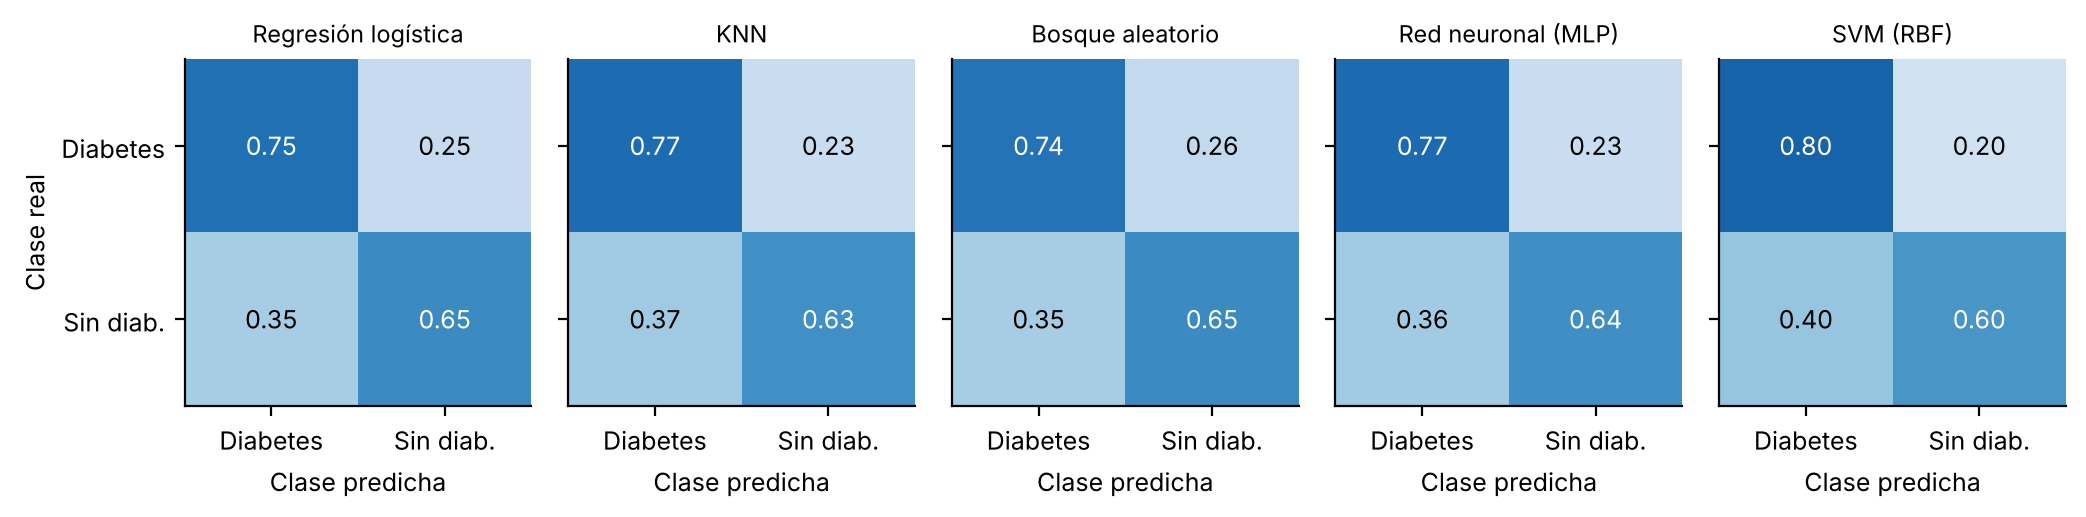

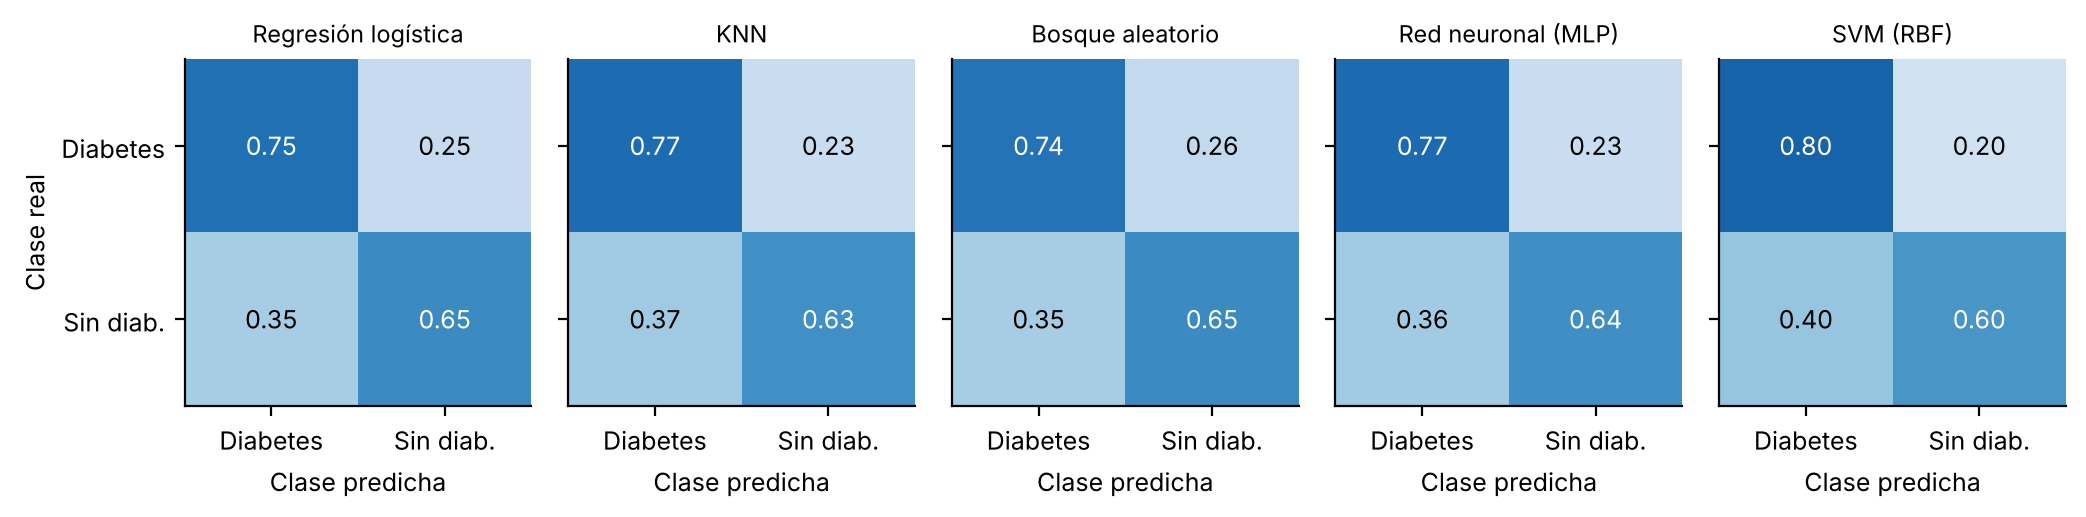

In [21]:
fig, ejes = plt.subplots(1, 5, figsize=(10.5, 2.3), sharey=True)
for ax, (nombre, modelo) in zip(ejes, finales.items()):
    m = confusion_matrix(y_pru, modelo.predict(X_pru), labels=[1, 0], normalize="true")
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center",
                    color="white" if m[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Diabetes", "Sin diab."])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Diabetes", "Sin diab."])
    ax.set_xlabel("Clase predicha"); ax.set_title(nombre, fontsize=8.5)
    ax.grid(False)
ejes[0].set_ylabel("Clase real")
fig.tight_layout()
fig.savefig("figuras/matrices_confusion_normalizadas.pdf", bbox_inches="tight")
fig.savefig("figuras/matrices_confusion_normalizadas.png", dpi=200, bbox_inches="tight")
fig

### LinearSVC frente a la SVM con kernel RBF

La realimentación sugería considerar `LinearSVC`, que escala casi linealmente con el número de muestras. Aquí se compara con la SVM RBF elegida: `LinearSVC` se valida con los mismos pliegues de la submuestra y luego se ajusta con **todo** el conjunto de entrenamiento (274.031 registros).

In [22]:
from sklearn.svm import LinearSVC

filas = []
for C in [0.01, 0.1, 1]:
    pipe = crear_pipeline(LinearSVC(C=C, class_weight="balanced", max_iter=5000, random_state=SEMILLA),
                          CODIFICACION["SVM (RBF)"])
    res = evaluar_cv(pipe)
    filas.append({"C": C, **resumen(res)})
tabla_lsvc_cv = pd.DataFrame(filas)
print(tabla_lsvc_cv.to_string(index=False))

C_lsvc = tabla_lsvc_cv.loc[tabla_lsvc_cv["AUC"].str[:4].astype(float).idxmax(), "C"]
lsvc = crear_pipeline(LinearSVC(C=C_lsvc, class_weight="balanced", max_iter=5000, random_state=SEMILLA),
                      CODIFICACION["SVM (RBF)"])
t0 = time.time(); lsvc.fit(X_ent, y_ent); t_lsvc = time.time() - t0
fila_rbf = tabla_final.loc[tabla_final["Modelo"] == "SVM (RBF)"].iloc[0]
pred = lsvc.predict(X_pru)
tabla_lsvc = pd.DataFrame([
    {"Modelo": f"LinearSVC (C={C_lsvc}), 274.031 registros", "AUC prueba": round(roc_auc_score(y_pru, lsvc.decision_function(X_pru)), 2),
     "Sensibilidad prueba": round(recall_score(y_pru, pred), 2), "Especificidad prueba": round(recall_score(y_pru, pred, pos_label=0), 2),
     "Tiempo ajuste + prueba (s)": round(t_lsvc, 1)},
    {"Modelo": "SVC RBF (C=1, gamma=0.01), 40.000 registros", "AUC prueba": fila_rbf["AUC prueba"],
     "Sensibilidad prueba": fila_rbf["Sensibilidad prueba"], "Especificidad prueba": fila_rbf["Especificidad prueba"],
     "Tiempo ajuste + prueba (s)": fila_rbf["Tiempo ajuste + prueba (s)"]}])
tabla_lsvc.to_csv("resultados/linearsvc_vs_rbf.csv", index=False)
tabla_lsvc

   C         AUC Sensibilidad Especificidad          F1
0.01 0.75 ± 0.01  0.73 ± 0.02   0.65 ± 0.01 0.39 ± 0.01
0.10 0.75 ± 0.01  0.73 ± 0.02   0.65 ± 0.01 0.39 ± 0.01
1.00 0.75 ± 0.01  0.73 ± 0.02   0.65 ± 0.01 0.39 ± 0.01


,Modelo,AUC prueba,Sensibilidad prueba,Especificidad prueba,Tiempo ajuste + prueba (s)
0,"LinearSVC (C=0.01), 274.031 registros",0.76,0.73,0.66,1.3
1,"SVC RBF (C=1, gamma=0.01), 40.000 registros",0.77,0.80,0.60,298.8


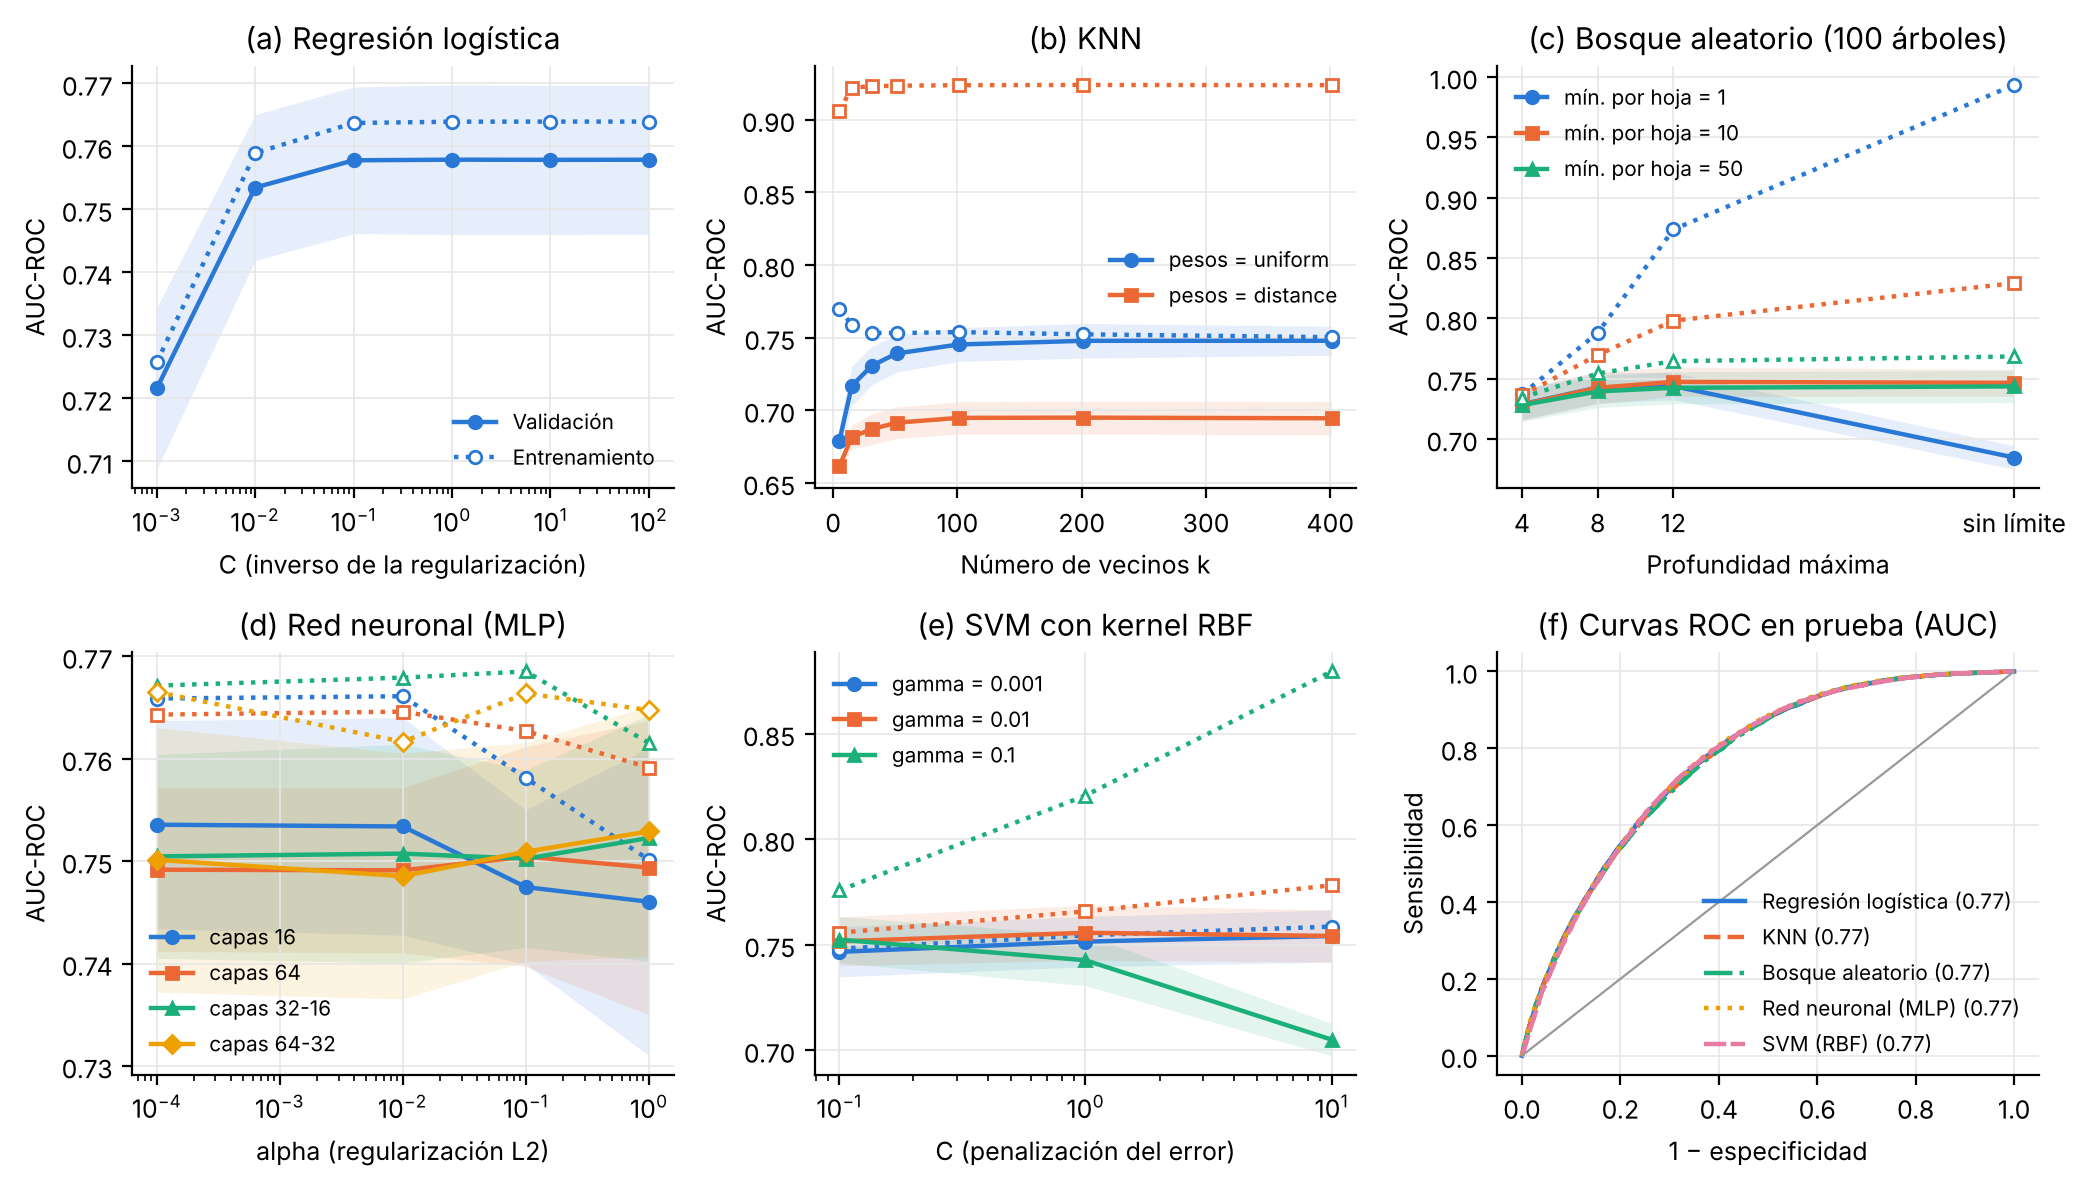

In [23]:
# Panel (f): curvas ROC en el conjunto de prueba, y guardado de la figura completa
ax = ejes_hiper[5]
ax.set_axis_on()
estilos = ["-", "--", "-.", ":", (0, (5, 1))]
for i, (nombre, (fpr, tpr, _)) in enumerate(roc.items()):
    auc = float(tabla_final.loc[tabla_final["Modelo"] == nombre, "AUC prueba"].iloc[0])
    ax.plot(fpr, tpr, color=COLORES[i], linestyle=estilos[i], label=f"{nombre} ({auc:.2f})")
ax.plot([0, 1], [0, 1], color="#999999", linewidth=0.8)
ax.set(title="(f) Curvas ROC en prueba (AUC)", xlabel="1 − especificidad",
       ylabel="Sensibilidad")
ax.legend(loc="lower right")
fig_hiper.tight_layout()
fig_hiper.savefig("figuras/hiperparametros_y_roc.pdf", bbox_inches="tight")
fig_hiper.savefig("figuras/hiperparametros_y_roc.png", dpi=200, bbox_inches="tight")
fig_hiper

## 7. Resumen

La tabla siguiente es la que se reporta en el informe. Los dos modelos con mayor AUC de validación son los que pasan a la fase de reducción de dimensión (sección 2).

In [24]:
orden = tabla_final.assign(auc_val=[tablas_cv[n]["mean_test_auc"].max() for n in tabla_final["Modelo"]])
orden = orden.sort_values("auc_val", ascending=False)
print("Modelos ordenados por AUC de validación:")
print(orden[["Modelo", "AUC ent.", "AUC val.", "AUC prueba", "Sensibilidad val.",
             "Sensibilidad prueba", "Especificidad prueba", "F1 prueba"]].to_string(index=False))
print("\nLos dos mejores modelos:", ", ".join(orden["Modelo"].head(2)))

Modelos ordenados por AUC de validación:
             Modelo    AUC ent.    AUC val.  AUC prueba Sensibilidad val.  Sensibilidad prueba  Especificidad prueba  F1 prueba
Regresión logística 0.76 ± 0.00 0.76 ± 0.01        0.77       0.75 ± 0.01                 0.75                  0.65        0.4
          SVM (RBF) 0.77 ± 0.00 0.76 ± 0.01        0.77       0.78 ± 0.01                 0.80                  0.60        0.4
 Red neuronal (MLP) 0.77 ± 0.00 0.75 ± 0.01        0.77       0.74 ± 0.03                 0.77                  0.64        0.4
                KNN 0.75 ± 0.00 0.75 ± 0.01        0.77       0.74 ± 0.01                 0.77                  0.63        0.4
   Bosque aleatorio 0.80 ± 0.00 0.75 ± 0.01        0.77       0.72 ± 0.02                 0.74                  0.65        0.4

Los dos mejores modelos: Regresión logística, SVM (RBF)
